# UTS Deep Learning – Prediksi Volume Lalu Lintas I-94 dengan LSTM

**Nama:** Muhammad Nabil Virzatullah  
**NIM:** 202432062  
**Kelas:** B  
**Dosen:** Dr. Dra. Dwina Kuswardani, M.Kom  
**Topik:** Time-Series Forecasting (NIM genap)  
**Algoritma:** LSTM (Long Short-Term Memory)  
**Dataset:** Metro Interstate Traffic Volume (Kaggle) – 48.204 baris, Okt 2012 – Sep 2018  

**Tujuan:** memprediksi `traffic_volume` (jumlah kendaraan per jam) satu jam ke depan berdasarkan data 24 jam terakhir.

## 1. Import Library dan Pengaturan Awal

In [17]:
#202432062_MuhammadNabilVirzatullah
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["grid.color"] = "gray"

print("Versi TensorFlow:", tf.__version__)

Versi TensorFlow: 2.21.0


## 2. Membaca dan Memahami Data

In [18]:
#202432062_MuhammadNabilVirzatullah
# Upload file Metro_Interstate_Traffic_Volume.csv ke /content (atau ganti path sesuai lokasi file)
df = pd.read_csv("/content/Metro_Interstate_Traffic_Volume.csv")

print("Jumlah baris & kolom:", df.shape)
display(df.head())
df.info()

Jumlah baris & kolom: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


In [19]:
#202432062_MuhammadNabilVirzatullah
display(df.describe())
print("\nMissing value per kolom:")
print(df.isna().sum())
print("\nDistribusi weather_main:")
print(df["weather_main"].value_counts())

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000



Missing value per kolom:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Distribusi weather_main:
weather_main
Clouds          15164
Clear           13391
Mist             5950
Rain             5672
Snow             2876
Drizzle          1821
Haze             1360
Thunderstorm     1034
Fog               912
Smoke              20
Squall              4
Name: count, dtype: int64


## 3. Pembersihan Data

In [20]:
#202432062_MuhammadNabilVirzatullah
df["date_time"] = pd.to_datetime(df["date_time"])
df = df.sort_values("date_time").reset_index(drop=True)

# Label hari libur diberlakukan ke semua jam pada tanggal yang sama
df["is_holiday"] = df["holiday"].notna()
df["is_holiday"] = df.groupby(df["date_time"].dt.date)["is_holiday"].transform("max").astype(int)

n_awal = len(df)
df = df.drop_duplicates(subset="date_time", keep="first")
print("Setelah hapus timestamp duplikat :", len(df))
df = df[df["temp"] > 0]
print("Setelah hapus temp = 0 K         :", len(df))
df = df[df["rain_1h"] < 100]
print("Setelah hapus rain_1h ekstrem    :", len(df))
df = df[df["traffic_volume"] > 0]
print("Setelah hapus traffic_volume = 0 :", len(df))
df = df.reset_index(drop=True)
print("Total baris dibuang:", n_awal - len(df))

Setelah hapus timestamp duplikat : 40575
Setelah hapus temp = 0 K         : 40565
Setelah hapus rain_1h ekstrem    : 40564
Setelah hapus traffic_volume = 0 : 40562
Total baris dibuang: 7642


## 4. Eksplorasi Data (EDA)

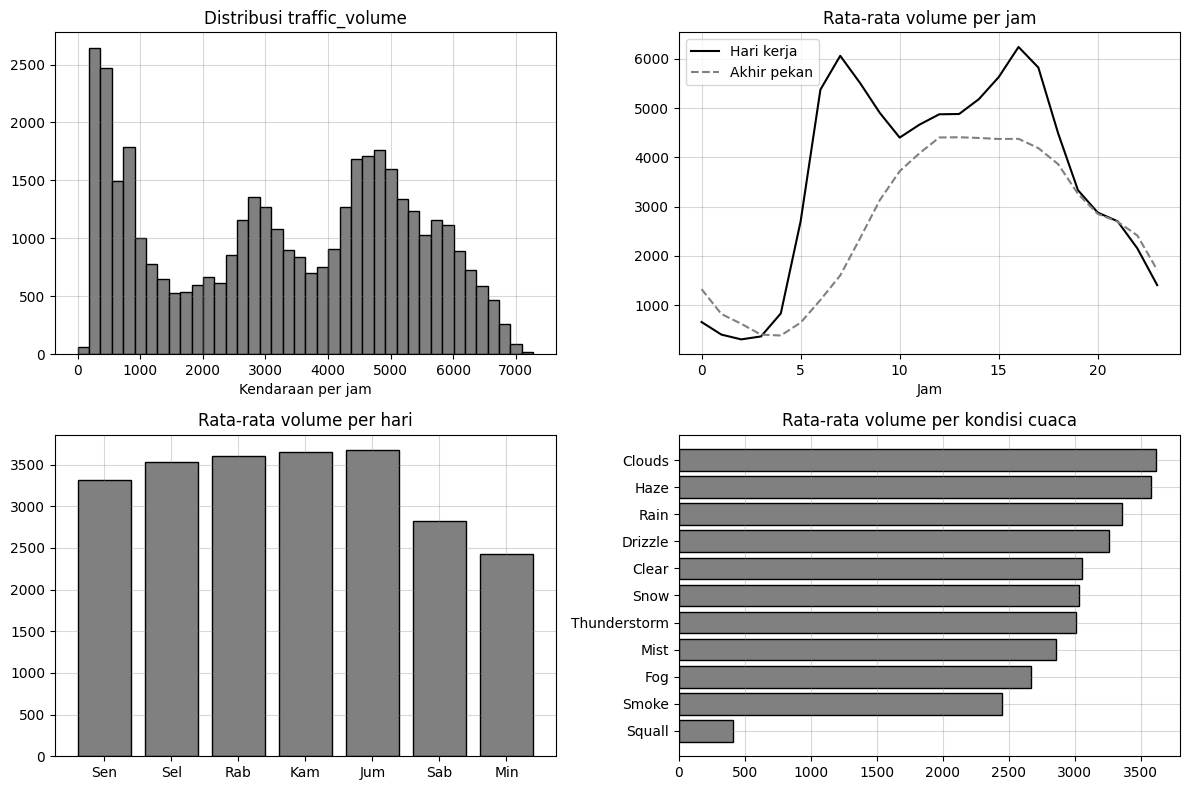

Rata-rata volume hari libur    : 2559
Rata-rata volume bukan libur   : 3314

Korelasi dengan traffic_volume:
temp              0.139
rain_1h          -0.013
snow_1h          -0.002
clouds_all        0.078
traffic_volume    1.000
Name: traffic_volume, dtype: float64


In [21]:
#202432062_MuhammadNabilVirzatullah
df["hour"] = df["date_time"].dt.hour
df["dayofweek"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month
df["weekend"] = df["dayofweek"] >= 5

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].hist(df["traffic_volume"], bins=40, color="gray", edgecolor="black")
ax[0, 0].set_title("Distribusi traffic_volume")
ax[0, 0].set_xlabel("Kendaraan per jam")

jam = df.groupby(["weekend", "hour"])["traffic_volume"].mean().unstack(0)
ax[0, 1].plot(jam.index, jam[False], color="black", label="Hari kerja")
ax[0, 1].plot(jam.index, jam[True], color="gray", linestyle="--", label="Akhir pekan")
ax[0, 1].set_title("Rata-rata volume per jam")
ax[0, 1].set_xlabel("Jam"); ax[0, 1].legend()

hari = df.groupby("dayofweek")["traffic_volume"].mean()
ax[1, 0].bar(["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"], hari.values, color="gray", edgecolor="black")
ax[1, 0].set_title("Rata-rata volume per hari")

cuaca = df.groupby("weather_main")["traffic_volume"].mean().sort_values()
ax[1, 1].barh(cuaca.index, cuaca.values, color="gray", edgecolor="black")
ax[1, 1].set_title("Rata-rata volume per kondisi cuaca")

plt.tight_layout()
plt.show()

print("Rata-rata volume hari libur    :", round(df[df.is_holiday == 1]["traffic_volume"].mean()))
print("Rata-rata volume bukan libur   :", round(df[df.is_holiday == 0]["traffic_volume"].mean()))
print("\nKorelasi dengan traffic_volume:")
print(df[["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]].corr()["traffic_volume"].round(3))

**Analisis EDA.** Pola volume lalu lintas sangat dipengaruhi waktu: pada hari kerja terdapat dua puncak (jam sibuk pagi dan sore), sedangkan akhir pekan hanya satu puncak yang lebih rendah. Korelasi variabel cuaca numerik terhadap volume lemah, sehingga informasi paling kuat berasal dari pola waktu dan riwayat volume jam-jam sebelumnya. Inilah alasan model sekuensial (LSTM) dengan jendela waktu digunakan.

## 5. Rekayasa Fitur

In [22]:
#202432062_MuhammadNabilVirzatullah
fitur = pd.DataFrame({
    "date_time"     : df["date_time"],
    "traffic_volume": df["traffic_volume"].astype(float),
    "temp_c"        : df["temp"] - 273.15,
    "rain_log"      : np.log1p(df["rain_1h"]),
    "snow_log"      : np.log1p(df["snow_1h"]),
    "clouds_all"    : df["clouds_all"].astype(float),
    "is_holiday"    : df["is_holiday"].astype(float),
    # Fitur waktu siklik (sin/cos) agar jam 23 dan jam 0 tetap berdekatan
    "hour_sin"      : np.sin(2 * np.pi * df["hour"] / 24),
    "hour_cos"      : np.cos(2 * np.pi * df["hour"] / 24),
    "dow_sin"       : np.sin(2 * np.pi * df["dayofweek"] / 7),
    "dow_cos"       : np.cos(2 * np.pi * df["dayofweek"] / 7),
    "month_sin"     : np.sin(2 * np.pi * (df["month"] - 1) / 12),
    "month_cos"     : np.cos(2 * np.pi * (df["month"] - 1) / 12),
})
cuaca_oh = pd.get_dummies(df["weather_main"], prefix="w", dtype=float)
fitur = pd.concat([fitur, cuaca_oh], axis=1)

nama_fitur = [c for c in fitur.columns if c != "date_time"]
print("Jumlah fitur per time step:", len(nama_fitur))
print(nama_fitur)

Jumlah fitur per time step: 23
['traffic_volume', 'temp_c', 'rain_log', 'snow_log', 'clouds_all', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'w_Clear', 'w_Clouds', 'w_Drizzle', 'w_Fog', 'w_Haze', 'w_Mist', 'w_Rain', 'w_Smoke', 'w_Snow', 'w_Squall', 'w_Thunderstorm']


## 6. Pembentukan Jendela Waktu (Sliding Window)

In [23]:
#202432062_MuhammadNabilVirzatullah
WINDOW = 24   # model melihat 24 jam terakhir untuk memprediksi jam berikutnya

waktu = fitur["date_time"].values
selisih = waktu[WINDOW:] - waktu[:-WINDOW]
# Jendela valid hanya jika 24 jam tersebut berurutan tanpa celah data
idx_target = np.where(selisih == np.timedelta64(WINDOW, "h"))[0] + WINDOW

print("Jumlah baris data bersih :", len(fitur))
print("Jumlah jendela valid     :", len(idx_target))

Jumlah baris data bersih : 40562
Jumlah jendela valid     : 28767


## 7. Pembagian Data Kronologis dan Normalisasi

In [24]:
#202432062_MuhammadNabilVirzatullah
n = len(idx_target)
i_val = int(n * 0.70)
i_test = int(n * 0.85)

tr_idx = idx_target[:i_val]
va_idx = idx_target[i_val:i_test]
te_idx = idx_target[i_test:]

# Statistik normalisasi HANYA dari data latih (mencegah kebocoran data)
batas_latih = fitur["date_time"].iloc[tr_idx[-1]]
kolom_num = ["traffic_volume", "temp_c", "rain_log", "snow_log", "clouds_all"]
ref = fitur[fitur["date_time"] <= batas_latih]
mu = ref[kolom_num].mean()
sd = ref[kolom_num].std()

F = fitur[nama_fitur].copy()
F[kolom_num] = (F[kolom_num] - mu) / sd
F = F.values.astype("float32")

offset = np.arange(-WINDOW, 0)
def buat_window(idx):
    X = F[idx[:, None] + offset[None, :]]      # (jumlah_sampel, WINDOW, jumlah_fitur)
    y = F[idx, 0]                              # kolom 0 = traffic_volume ternormalisasi
    return X, y

Xtr, ytr = buat_window(tr_idx)
Xva, yva = buat_window(va_idx)
Xte, yte = buat_window(te_idx)

print("Train :", Xtr.shape, "|", fitur['date_time'].iloc[tr_idx[0]], "->", fitur['date_time'].iloc[tr_idx[-1]])
print("Val   :", Xva.shape, "|", fitur['date_time'].iloc[va_idx[0]], "->", fitur['date_time'].iloc[va_idx[-1]])
print("Test  :", Xte.shape, "|", fitur['date_time'].iloc[te_idx[0]], "->", fitur['date_time'].iloc[te_idx[-1]])

def denorm(v):
    return v * sd["traffic_volume"] + mu["traffic_volume"]

Train : (20136, 24, 23) | 2012-10-04 18:00:00 -> 2017-09-15 04:00:00
Val   : (4315, 24, 23) | 2017-09-15 05:00:00 -> 2018-03-30 21:00:00
Test  : (4316, 24, 23) | 2018-03-30 22:00:00 -> 2018-09-30 23:00:00


## 8. Baseline sebagai Pembanding

In [25]:
#202432062_MuhammadNabilVirzatullah
def metrik(y, p):
    mae = np.mean(np.abs(y - p))
    rmse = np.sqrt(np.mean((y - p) ** 2))
    r2 = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
    return mae, rmse, r2

y_test_asli = denorm(yte)

# Baseline 1: persistence -> prediksi = volume 1 jam sebelumnya
pred_persist = denorm(Xte[:, -1, 0])
# Baseline 2: seasonal naive -> prediksi = volume pada jam yang sama kemarin (24 jam lalu)
pred_seasonal = denorm(Xte[:, 0, 0])

hasil = {}
hasil["Baseline 1: Persistence (t-1)"] = metrik(y_test_asli, pred_persist)
hasil["Baseline 2: Seasonal naive (t-24)"] = metrik(y_test_asli, pred_seasonal)

for k, v in hasil.items():
    print(f"{k:36s} MAE={v[0]:8.3f}  RMSE={v[1]:8.3f}  R2={v[2]:6.3f}")

Baseline 1: Persistence (t-1)        MAE= 585.095  RMSE= 813.177  R2= 0.831
Baseline 2: Seasonal naive (t-24)    MAE= 540.338  RMSE=1018.716  R2= 0.735


## 9. Membangun Model LSTM

In [26]:
#202432062_MuhammadNabilVirzatullah
n_fitur = Xtr.shape[2]

model = tf.keras.Sequential([
    tf.keras.Input(shape=(WINDOW, n_fitur)),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"],
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        22,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,641 (96.25 KB)

 Trainable params: 24,641 (96.25 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Training Model

In [11]:
#202432062_MuhammadNabilVirzatullah
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

history = model.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop],
    verbose=2,
)

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print("\nEpoch berjalan :", len(history.history["loss"]))
print("Epoch terbaik  :", best_epoch, "| val_loss =", round(min(history.history["val_loss"]), 4))

Epoch 1/50
315/315 - 9s - 30ms/step - loss: 0.1614 - mae: 0.2907 - val_loss: 0.0551 - val_mae: 0.1678
Epoch 2/50
315/315 - 5s - 15ms/step - loss: 0.0506 - mae: 0.1682 - val_loss: 0.0396 - val_mae: 0.1387
Epoch 3/50
315/315 - 7s - 21ms/step - loss: 0.0379 - mae: 0.1447 - val_loss: 0.0325 - val_mae: 0.1275
Epoch 4/50
315/315 - 9s - 30ms/step - loss: 0.0327 - mae: 0.1337 - val_loss: 0.0283 - val_mae: 0.1167
Epoch 5/50
315/315 - 6s - 20ms/step - loss: 0.0291 - mae: 0.1246 - val_loss: 0.0264 - val_mae: 0.1159
Epoch 6/50
315/315 - 5s - 15ms/step - loss: 0.0271 - mae: 0.1198 - val_loss: 0.0256 - val_mae: 0.1139
Epoch 7/50
315/315 - 7s - 21ms/step - loss: 0.0256 - mae: 0.1162 - val_loss: 0.0222 - val_mae: 0.1017
Epoch 8/50
315/315 - 5s - 16ms/step - loss: 0.0246 - mae: 0.1130 - val_loss: 0.0243 - val_mae: 0.1094
Epoch 9/50
315/315 - 6s - 18ms/step - loss: 0.0238 - mae: 0.1112 - val_loss: 0.0218 - val_mae: 0.1015
Epoch 10/50
315/315 - 6s - 18ms/step - loss: 0.0229 - mae: 0.1081 - val_loss: 0.02

## 11. Visualisasi Riwayat Training

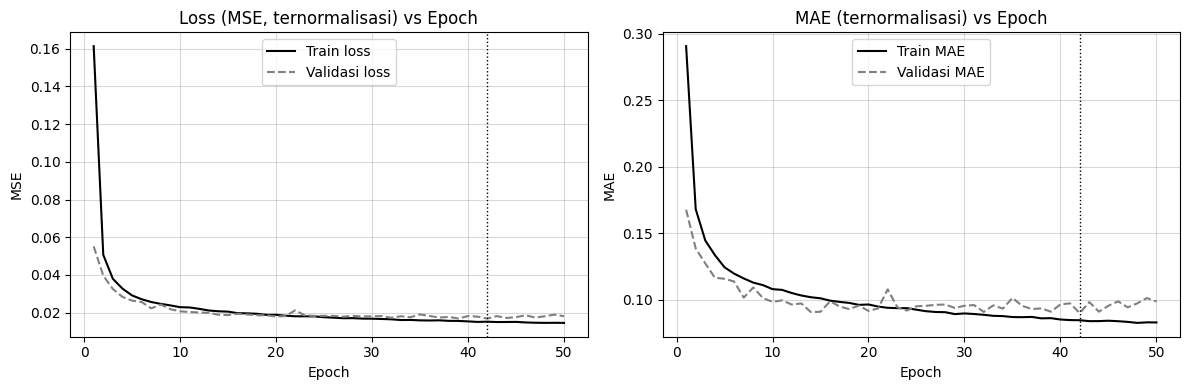

In [12]:
#202432062_MuhammadNabilVirzatullah
h = history.history
ep = np.arange(1, len(h["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, h["loss"], color="black", label="Train loss")
ax[0].plot(ep, h["val_loss"], color="gray", linestyle="--", label="Validasi loss")
ax[0].axvline(best_epoch, color="black", linestyle=":", linewidth=1)
ax[0].set_title("Loss (MSE, ternormalisasi) vs Epoch")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE"); ax[0].legend()

ax[1].plot(ep, h["mae"], color="black", label="Train MAE")
ax[1].plot(ep, h["val_mae"], color="gray", linestyle="--", label="Validasi MAE")
ax[1].axvline(best_epoch, color="black", linestyle=":", linewidth=1)
ax[1].set_title("MAE (ternormalisasi) vs Epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("MAE"); ax[1].legend()

plt.tight_layout()
plt.show()

## 12. Evaluasi pada Data Uji

In [13]:
#202432062_MuhammadNabilVirzatullah
pred_lstm = denorm(model.predict(Xte, verbose=0).flatten())
hasil["LSTM"] = metrik(y_test_asli, pred_lstm)

print(f"{'Model':36s} {'MAE':>9s} {'RMSE':>9s} {'R2':>7s}")
for k, v in hasil.items():
    print(f"{k:36s} {v[0]:9.3f} {v[1]:9.3f} {v[2]:7.3f}")

terbaik_baseline = min(hasil["Baseline 1: Persistence (t-1)"][1], hasil["Baseline 2: Seasonal naive (t-24)"][1])
perbaikan = (terbaik_baseline - hasil["LSTM"][1]) / terbaik_baseline * 100
print(f"\nRMSE LSTM {perbaikan:.1f}% lebih baik dibanding baseline terbaik")

Model                                      MAE      RMSE      R2
Baseline 1: Persistence (t-1)          585.095   813.177   0.831
Baseline 2: Seasonal naive (t-24)      540.338  1018.716   0.735
LSTM                                   161.122   224.661   0.987

RMSE LSTM 72.4% lebih baik dibanding baseline terbaik


## 13. Visualisasi Aktual vs Prediksi

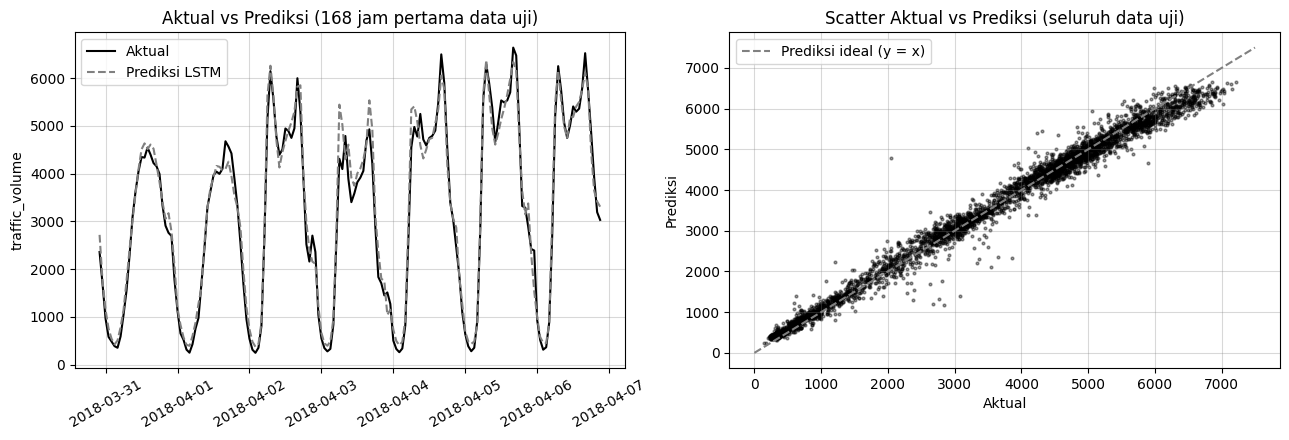

In [14]:
#202432062_MuhammadNabilVirzatullah
waktu_test = fitur["date_time"].iloc[te_idx].reset_index(drop=True)
N = 168  # satu minggu pertama pada data uji

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(waktu_test[:N], y_test_asli[:N], color="black", label="Aktual")
ax[0].plot(waktu_test[:N], pred_lstm[:N], color="gray", linestyle="--", label="Prediksi LSTM")
ax[0].set_title("Aktual vs Prediksi (168 jam pertama data uji)")
ax[0].set_ylabel("traffic_volume"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=30)

ax[1].scatter(y_test_asli, pred_lstm, s=4, color="black", alpha=0.4)
lim = [0, 7500]
ax[1].plot(lim, lim, color="gray", linestyle="--", label="Prediksi ideal (y = x)")
ax[1].set_xlabel("Aktual"); ax[1].set_ylabel("Prediksi")
ax[1].set_title("Scatter Aktual vs Prediksi (seluruh data uji)"); ax[1].legend()

plt.tight_layout()
plt.show()

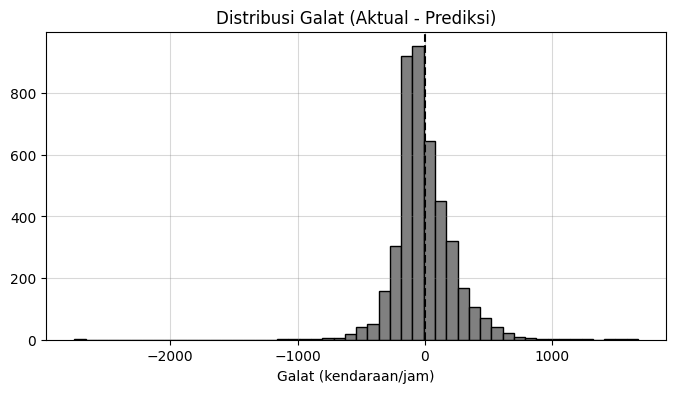

Rata-rata galat : -7.55
Std galat       : 224.53


In [15]:
#202432062_MuhammadNabilVirzatullah
galat = y_test_asli - pred_lstm
plt.figure(figsize=(8, 4))
plt.hist(galat, bins=50, color="gray", edgecolor="black")
plt.axvline(0, color="black", linestyle="--")
plt.title("Distribusi Galat (Aktual - Prediksi)")
plt.xlabel("Galat (kendaraan/jam)")
plt.show()

print("Rata-rata galat :", round(galat.mean(), 2))
print("Std galat       :", round(galat.std(), 2))

## 14. Verifikasi Perhitungan Manual LSTM (1 input, 1 time step)

In [16]:
#202432062_MuhammadNabilVirzatullah
# Hitung 1 time step LSTM dengan 1 input x_t dan 1 hidden unit (sama dengan perhitungan manual pada laporan BAB 2)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x_t, h_prev, c_prev = 0.8, 0.5, 0.3
Wf, bf = (0.6, 0.4), 0.1     # (bobot h_{t-1}, bobot x_t), bias
Wi, bi = (0.5, 0.7), 0.0
Wc, bc = (0.9, 0.3), 0.1
Wo, bo = (0.4, 0.8), 0.2

f_t  = sigmoid(Wf[0] * h_prev + Wf[1] * x_t + bf)
i_t  = sigmoid(Wi[0] * h_prev + Wi[1] * x_t + bi)
c_hat = np.tanh(Wc[0] * h_prev + Wc[1] * x_t + bc)
c_t  = f_t * c_prev + i_t * c_hat
o_t  = sigmoid(Wo[0] * h_prev + Wo[1] * x_t + bo)
h_t  = o_t * np.tanh(c_t)

for nama, nilai in [("f_t", f_t), ("i_t", i_t), ("C~_t", c_hat), ("C_t", c_t), ("o_t", o_t), ("h_t", h_t)]:
    print(f"{nama:5s} = {nilai:.4f}")

f_t   = 0.6726
i_t   = 0.6921
C~_t  = 0.6584
C_t   = 0.6575
o_t   = 0.7389
h_t   = 0.4261


## 15. Ringkasan dan Keterbatasan

- Model: LSTM(64) + Dropout(0.2) + Dense(32, ReLU) + Dense(1), input jendela 24 jam, target volume 1 jam ke depan.
- Pembagian data kronologis 70/15/15 tanpa pengacakan, normalisasi hanya dari data latih.
- Pembanding: persistence dan seasonal naive.

**Keterbatasan:** data hanya dari satu stasiun; terdapat celah data (sekitar 10 bulan pada 2014–2015) sehingga jendela yang melintasi celah dibuang; prediksi hanya satu langkah ke depan; belum dilakukan penyetelan hyperparameter ekstensif.